# Module 2 — Credit Risk: run the whole module

**How to use:**
- **Run all** to run the full module in order, or run a single cell to run one step.
- Each cell runs one task notebook in full and shows all its charts and main tables here; the task notebook itself shows every table.
- Every task notebook also runs on its own: open it from `notebooks/` and run all.

**Order matters:** later tasks read the files earlier tasks save in `outputs/taskN/`. Run the tasks in order, or rely on the files saved last time.

| Step | Notebook | Status |
| --- | --- | --- |
| 0. Data check | `helpers/m02_data.py` | Built |
| 1. Task 1 — Predict the Probability of Default | `notebooks/m02_task1_pd_model.ipynb` | Built |
| 2. Task 2 — PD per loan and risk bands | `notebooks/m02_task2_pd_bands.ipynb` | Built |
| 3. Task 3 — Expected Credit Loss and decision | `notebooks/m02_task3_ecl_decision.ipynb` | Built |
| Final. Output workbook | `helpers/m02_final_output.py` → `outputs/FINAL_M2_module_output.xlsx` | Built |

Findings with charts: `reports/`. Status: `docs/progress.md`.


## Setup
Moves into the module folder so the paths below work, both locally and in Google Colab.
- **Colab:** upload the whole unzipped project folder (any name) to Google Drive; the cell below finds it. Then run all cells.

In [1]:
import os
import sys
from pathlib import Path

# ---- Find the project folder: any folder name works, on your computer or in Google Colab ----
# The project folder is the one holding run_novafin.ipynb and data/.
IN_COLAB = "google.colab" in sys.modules
is_project = lambda p: (p / "run_novafin.ipynb").exists() and (p / "data").is_dir()
places = [p for p in [Path.cwd(), *Path.cwd().parents] if is_project(p)]
if IN_COLAB and not places:                                 # Colab starts outside the project: look in /content, then in Google Drive
    for base in [Path("/content"), Path("/content/drive/MyDrive")]:
        if "drive" in base.parts:
            from google.colab import drive
            drive.mount("/content/drive")                   # asks for access to your Google Drive
        for depth in ["", "*/", "*/*/", "*/*/*/"]:
            places += [f.parent for f in sorted(base.glob(depth + "run_novafin.ipynb")) if is_project(f.parent)]
        if places:
            break
if not places:
    raise FileNotFoundError("Project folder not found: unzip the whole project and keep run_novafin.ipynb, data/ and the module folders together (see HOW_TO_RUN.md).")
PROJECT_ROOT = places[0]
os.chdir(PROJECT_ROOT / "module_02_credit_risk")                  # the paths below start from the module folder
print("Working folder:", Path.cwd().name)

Working folder: module_02_credit_risk


## 0. Data check
Is `nova_loans.csv` complete and clean? Prints the identifier column, rows, missing values, duplicates, default rate, the Retail/Corporate mix and the loan book in ₹ crore.

In [2]:
%run helpers/m02_data.py

Identifier column: Loan_ID
rows: 5000
missing_values: 0
duplicate_rows: 0
default_rate: 0.199
customer_type: {'Retail': 3694, 'Corporate': 1306}
loan_book_crore: 639.7
credit_score_range: (406, 850)
debt_to_income_above_1: 0
negative_money_values: 0


## 1. Task 1 — Predict the Probability of Default
Runs `notebooks/m02_task1_pd_model.ipynb`. Takes about 9 minutes: 7 models × 25 cross-validation rounds (three of them tune inside each round), the rebalancing comparison and a 1,000-resample bootstrap.
- the first look at the data, in ₹;
- champion (the bank's interest rate) vs five challengers on borrower fundamentals;
- the ₹ case, the final test on 1,000 unseen loans, and what drives default;
- saves `outputs/task1/FINAL_M2_T1_default_predictions.csv` and the chosen model for Task 2.

nbformat\__init__.py:96: MissingIDFieldWarning: Cell is missing an id field, this will become a hard error in future nbformat versions. You may want to use `normalize()` on your notebooks before validations (available since nbformat 5.1.4). Previous versions of nbformat are fixing this issue transparently, and will stop doing so in the future.
  validate(nb)


Project folder found
Outputs go to:  module_02_credit_risk/outputs/task1


,Check,Result
0,rows,5000
1,missing_values,0
2,duplicate_rows,0
3,default_rate,0.199
4,customer_type,"{'Retail': 3694, 'Corporate': 1306}"
5,loan_book_crore,639.7
6,credit_score_range,"(406, 850)"
7,debt_to_income_above_1,0
8,negative_money_values,0


,Plausibility check,Passed
0,Credit_Score within 300–900 (Indian bureau scale),True
1,Debt_to_Income between 0 and 1,True
2,Interest_Rate between 0% and 30%,True
3,Past_Default and Default_Flag are 0/1,True
4,Loan_Term_Months is a whole number of years,True
5,Money columns positive,True


,Input,Lowest group,Highest group,Gap (highest − lowest),Rates by group (low → high)
0,Interest_Rate,8.5%,41.9%,+33.4%,8.5% · 10.5% · 17.3% · 21.8% · 41.9%
1,Credit_Score,31.8%,10.0%,-21.9%,31.8% · 22.7% · 19.9% · 15.0% · 10.0%
2,Debt_to_Income,11.4%,32.5%,+21.1%,11.4% · 16.4% · 19.1% · 20.4% · 32.5%
3,Past_Default,17.7%,37.8%,+20.1%,0: 17.7% · 1: 37.8%
4,Loan_Amount,13.3%,31.0%,+17.7%,13.3% · 17.0% · 18.4% · 20.0% · 31.0%
5,Total_Debt_to_Income,12.4%,29.7%,+17.3%,12.4% · 16.1% · 20.6% · 20.9% · 29.7%
6,Loan_to_Income,13.2%,28.7%,+15.5%,13.2% · 15.0% · 18.6% · 24.2% · 28.7%
7,Collateral_Value,12.6%,26.9%,+14.3%,12.6% · 16.5% · 20.3% · 23.4% · 26.9%
8,Principal_to_Income,14.0%,23.3%,+9.3%,14.0% · 16.5% · 21.3% · 24.6% · 23.3%
9,Existing_Loan,17.7%,24.1%,+6.4%,17.7% · 17.6% · 19.5% · 20.8% · 24.1%


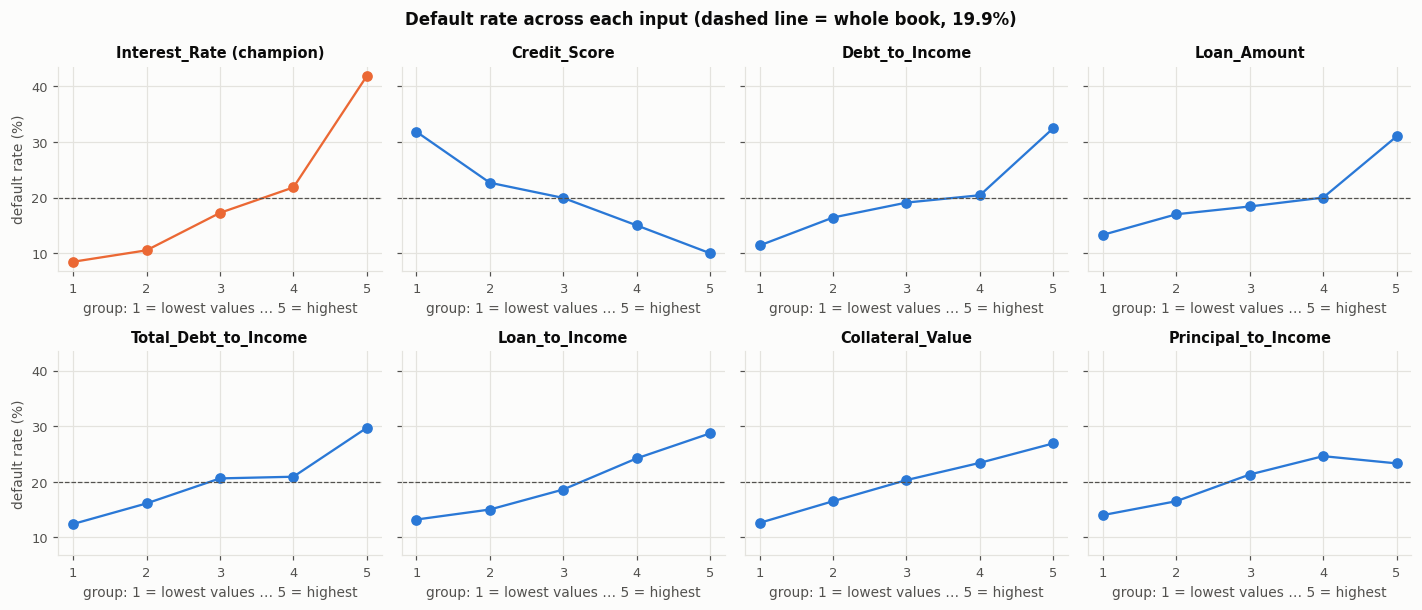

,Corporate,Retail,Whole book
Loans,"1,306","3,694","5,000"
₹ lent (crore),173.22,466.43,639.65
Default rate (count),20.0%,19.9%,19.9%
Default rate (money),25.6%,24.1%,24.5%
₹ lent to defaulters (crore),44.31,112.50,156.81
Loss at 40% LGD (crore),17.72,45.00,62.72
Average loan (₹ lakh),13.26,12.63,12.79
Average interest rate (%),9.54,9.52,9.52


Average loan: repaid ₹12.1 lakh, defaulted ₹15.7 lakh (defaulted loans are +30% larger on average)


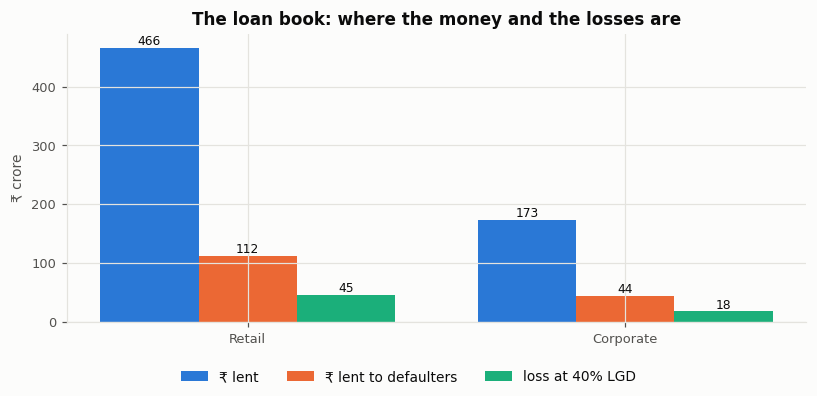

,Loans,Default_rate,Lent_crore
Collateral cover (fifths),,,
0.50–0.79,1000,17.6%,128.9
0.79–1.09,1000,19.4%,126.5
1.09–1.41,1000,21.9%,130.5
1.41–1.71,1000,20.3%,122.8
1.71–2.00,1000,20.5%,130.9


Under-collateralised loans (cover < 1): 1,665 of 5,000 (33%), ₹212.7 crore lent; their default rate 18.5% vs 20.7% for the rest


Loan_Term_Months,12,24,36,48,60,72,84
Loans,733,703,716,721,698,734,695
Default_rate,19.1%,19.2%,20.8%,20.4%,19.9%,20.4%,19.7%


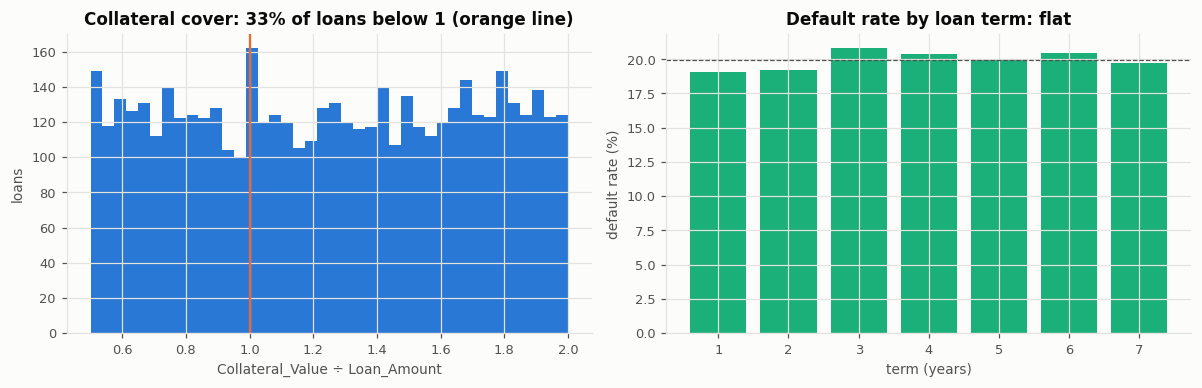

,Input,Source,Formula / meaning,Known at application?
0,Annual_Income,Given (brief's list),as given,Yes
1,Employment_Length,Given (brief's list),as given,Yes
2,Debt_to_Income,Given (brief's list),as given,Yes
3,Credit_Score,Given (brief's list),as given,Yes
4,Existing_Loan,Given (brief's list),as given,Yes
5,Loan_Amount,Given (brief's list),as given,Yes
6,Loan_Term_Months,Given (brief's list),as given,Yes
7,Collateral_Value,Given (brief's list),as given,Yes
8,Past_Default,Given (brief's list),as given,Yes
9,Sector_Risk,Given (brief's list),as given,Yes


Share of Interest_Rate explained by the 15 fundamentals (R²): 72.2%
→ the bank's price already reflects most of the fundamentals. A challenger must find what is left over.


,Training set,Test set,Whole book
Loans,"4,000.000","1,000.000","5,000.000"
Defaults,798.000,199.000,997.000
Default rate,0.200,0.199,0.199
Retail share,0.739,0.739,0.739
₹ lent (crore),511.802,127.851,639.653


Champion uses: ['Interest_Rate'] | Reference uses: ['Credit_Score']
Challengers (simplest → most complex): Lasso, Logistic regression, Decision tree, Random forest, LightGBM
Measures: Brier, ROC_AUC, Gini, KS, Log_loss, Average_PD, Actual_rate, Calibration_slope, Precision, Recall, F1


Champion: interest rate    done in   0.7s | Brier 0.1444 | ROC-AUC 0.702


Reference: credit score    done in   0.8s | Brier 0.1542 | ROC-AUC 0.632


... (2 outputs left out)

Decision tree              done in  12.8s | Brier 0.1494 | ROC-AUC 0.679


Random forest              done in  56.8s | Brier 0.1442 | ROC-AUC 0.718


LightGBM                   done in  75.7s | Brier 0.1445 | ROC-AUC 0.716


,Brier,ROC_AUC,Gini,KS,Log_loss,Average_PD,Actual_rate,Calibration_slope,Precision,Recall,F1
Model,,,,,,,,,,,
Champion: interest rate,0.1444,0.702,0.404,0.322,0.456,0.199,0.200,1.008,0.446,0.366,0.401
Reference: credit score,0.1542,0.632,0.264,0.213,0.483,0.200,0.200,1.018,0.370,0.190,0.251
Lasso,0.1411,0.731,0.462,0.363,0.445,0.202,0.200,1.032,0.432,0.436,0.433
Logistic regression,0.1413,0.730,0.460,0.363,0.445,0.200,0.200,0.965,0.432,0.437,0.434
Decision tree,0.1494,0.679,0.359,0.289,0.469,0.199,0.200,0.749,0.395,0.380,0.382
Random forest,0.1442,0.718,0.435,0.344,0.453,0.199,0.200,1.271,0.423,0.381,0.401
LightGBM,0.1445,0.716,0.431,0.341,0.454,0.198,0.200,0.842,0.406,0.420,0.412


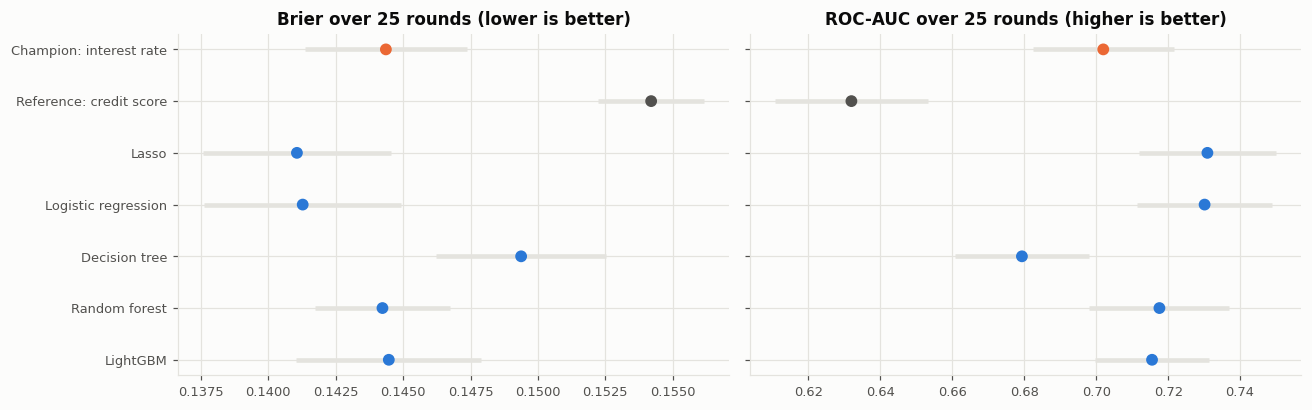

,Training,ROC-AUC,Brier,Average PD,Expected loss (₹ crore)
0,As the data is (chosen),0.730,0.1413,20.0%,50.1
1,Class-weighted,0.730,0.2089,44.9%,105.2
2,What actually happened,—,—,20.0%,50.0


,Train_ROC_AUC,CV_ROC_AUC,Train_Brier,CV_Brier,ROC-AUC gap,Overfits (gap > 0.05)?
Model,,,,,,
Champion: interest rate,0.702,0.702,0.1443,0.1444,-0.000,No
Reference: credit score,0.632,0.632,0.1541,0.1542,-0.000,No
Lasso,0.737,0.731,0.1398,0.1411,0.006,No
Logistic regression,0.737,0.730,0.1397,0.1413,0.007,No
Decision tree,0.729,0.679,0.1387,0.1494,0.049,No
Random forest,0.851,0.718,0.1249,0.1442,0.133,Yes
LightGBM,0.825,0.716,0.1220,0.1445,0.109,Yes


,Average gap,Smallest round,Largest round
Model,,,
Champion: interest rate,-0.000,-0.055,+0.038
Reference: credit score,-0.000,-0.060,+0.064
Lasso,+0.006,-0.053,+0.051
Logistic regression,+0.007,-0.052,+0.050
Decision tree,+0.049,+0.008,+0.080
Random forest,+0.133,+0.094,+0.168
LightGBM,+0.109,+0.074,+0.146


Limit 0.03 would rule out: ['Decision tree', 'Random forest', 'LightGBM']
Limit 0.05 would rule out: ['Random forest', 'LightGBM']
Limit 0.08 would rule out: ['Random forest', 'LightGBM']
Limit 0.10 would rule out: ['Random forest', 'LightGBM']
Limit 0.12 would rule out: ['Random forest']


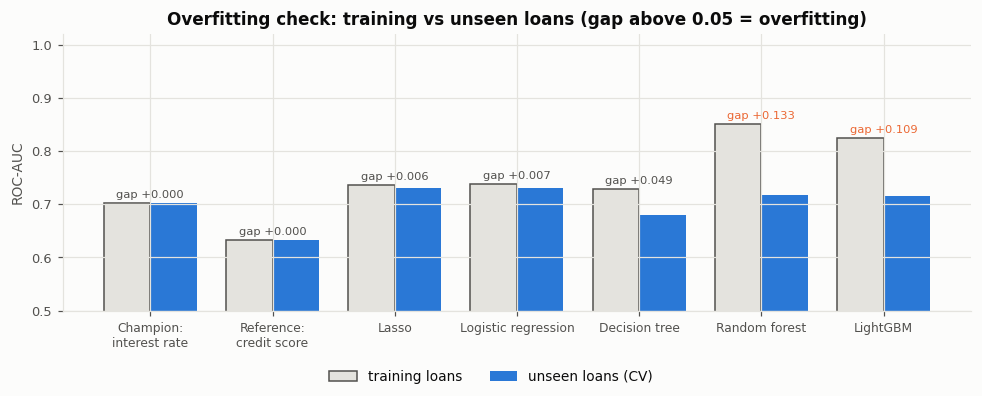

Each model minus the champion (Brier: negative = better; ROC-AUC, KS: positive = better)


,Model,Measure,Mean difference,Low,High,A better in rounds,Verdict
0,Reference: credit score,Brier,+0.0098,+0.0089,+0.0108,0,Worse than the champion
1,Reference: credit score,ROC_AUC,-0.0700,-0.0801,-0.0600,0,Worse than the champion
2,Reference: credit score,KS,-0.1089,-0.1269,-0.0909,0,Worse than the champion
3,Lasso,Brier,-0.0033,-0.0040,-0.0026,24,Beats the champion
4,Lasso,ROC_AUC,+0.0289,+0.0242,+0.0337,25,Beats the champion
5,Lasso,KS,+0.0411,+0.0297,+0.0525,22,Beats the champion
6,Logistic regression,Brier,-0.0031,-0.0038,-0.0024,24,Beats the champion
7,Logistic regression,ROC_AUC,+0.0282,+0.0235,+0.0328,25,Beats the champion
8,Logistic regression,KS,+0.0409,+0.0294,+0.0523,22,Beats the champion
9,Decision tree,Brier,+0.0050,+0.0037,+0.0063,2,Worse than the champion


Rule 1 - ruled out for overfitting: ['Random forest', 'LightGBM']
Rule 2 - best mean Brier among the rest: Lasso (0.1411)


,Model,Brier,Mean difference,Low,High,Within the noise of the best?
0,Lasso,0.1411,+0.0000,+0.0000,+0.0000,It is the best
1,Logistic regression,0.1413,+0.0002,+0.0001,+0.0004,No
2,Decision tree,0.1494,+0.0083,+0.0069,+0.0097,No


Rule 3 - models tied with the best: ['Lasso'] → simplest: Lasso

Chosen challenger: Lasso
Chosen model Lasso: Brier on training loans 0.1398, on unseen loans 0.1411; ROC-AUC on unseen loans 0.731


,Model,"Brier, training loans","Brier, unseen loans",Brier minus chosen,Brier 95% low,Brier 95% high,Chosen better on Brier (rounds of 25),"ROC-AUC, unseen loans",ROC-AUC minus chosen,ROC-AUC 95% low,ROC-AUC 95% high,Chosen better on ROC-AUC (rounds of 25)
0,Champion: interest rate,0.144272,0.144359,0.003299,0.002625,0.003974,24,0.702,-0.028946,-0.033688,-0.024203,25
1,Reference: credit score,0.154085,0.154198,0.013139,0.012126,0.014152,25,0.632,-0.098960,-0.107138,-0.090781,25
2,Logistic regression,0.139715,0.141273,0.000214,0.000061,0.000367,20,0.730,-0.000782,-0.001345,-0.000218,17
3,Decision tree,0.138712,0.149375,0.008316,0.006946,0.009686,25,0.679,-0.051557,-0.059482,-0.043631,25
4,Random forest,0.124895,0.144232,0.003172,0.002395,0.003950,25,0.718,-0.013339,-0.017364,-0.009315,22
5,LightGBM,0.122003,0.144467,0.003408,0.002786,0.004030,24,0.716,-0.015391,-0.018637,-0.012144,24


,Approve,Model,Loans approved,Defaults,Default rate,₹ lent (crore),₹ lent to defaulters (crore),Loss at 40% (crore)
0,50%,Champion: interest rate,2000,225,11.2%,190.4,23.5,9.42
1,50%,Reference: credit score,2000,281,14.1%,259.9,48.7,19.48
2,50%,Lasso,2000,188,9.4%,188.2,18.3,7.33
3,60%,Champion: interest rate,2400,294,12.2%,239.3,32.5,13.01
4,60%,Reference: credit score,2400,363,15.1%,311.2,61.8,24.73
5,60%,Lasso,2400,262,10.9%,240.2,29.0,11.60
6,70%,Champion: interest rate,2800,367,13.1%,293.8,42.3,16.94
7,70%,Reference: credit score,2800,448,16.0%,360.4,72.4,28.95
8,70%,Lasso,2800,342,12.2%,297.5,42.1,16.84
9,80%,Champion: interest rate,3200,465,14.5%,352.1,57.6,23.04


,Fewer defaults,Loss saved (₹ crore)
Approve,,
50%,37,+2.08
60%,32,+1.41
70%,25,+0.09
80%,14,-0.74
90%,5,-1.08


,Approval levels,Levels where the challenger saves money,Average saving (₹ crore)
0,30%–72%,43 of 43,+1.37
1,73%–79%,0 of 7,-0.88
2,80%–100%,0 of 21,-1.08


Rule 4 - the ₹ check (finding): Lasso saves money at every approval level up to 72%; from about 73% upward the champion's pricing loses less. Carried to Task 3, where the approval level is set.


,Champion approves,Champion default rate,Champion loans,Challenger loans at same rate,Extra loans,Extra ₹ lent (crore)
0,50%,11.2%,2000,2465,465,+60.0
1,60%,12.2%,2400,2812,412,+59.8
2,70%,13.1%,2800,3015,215,+38.1
3,80%,14.5%,3200,3297,97,+26.6
4,90%,16.5%,3600,3607,7,+8.9


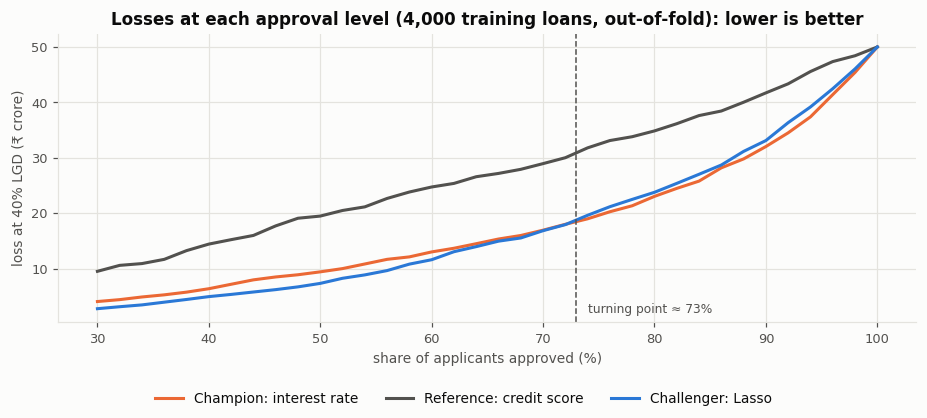

,Group,Loans,Actual default rate,Average rate charged (%),₹ lent (crore)
0,Priced as risky (rate ≥ median) but challenger PD < 10%,95,5.3%,9.59,8.2
1,Priced as safe (rate < median) but challenger PD > 30%,14,35.7%,8.82,1.6
2,All training loans,4000,20.0%,9.51,511.8


Median rate charged: 9.15%


Model,Champion: interest rate,Reference: credit score,Lasso
Measure,,,
Average_PD,0.2036,0.1992,0.2116
Brier,0.1432,0.1532,0.1406
Calibration_slope,1.0223,1.0619,1.1264
Gini,0.4370,0.2810,0.4829
KS,0.3469,0.2230,0.3824
Loss at 70% approval (₹ crore),4.0304,7.1205,4.2889
Precision,0.4222,0.3524,0.4009
ROC_AUC,0.7185,0.6405,0.7415
Recall,0.3819,0.1859,0.4372


,Challenger − champion,95% low,95% high,Verdict
Brier,-0.0025,-0.0063,+0.0010,Within the noise
ROC_AUC,+0.0230,-0.0022,+0.0472,Within the noise
Gini,+0.0459,-0.0044,+0.0945,Within the noise
KS,+0.0355,-0.0216,+0.0832,Within the noise
Average_PD,+0.0079,+0.0034,+0.0124,Information only
Calibration_slope,+0.1041,-0.0191,+0.2298,Information only
Recall,+0.0553,+0.0000,+0.1147,Within the noise
Precision,-0.0213,-0.0677,+0.0278,Within the noise
Loss at 70% approval (₹ crore),+0.2585,-0.7571,+0.9896,Within the noise


DeLong test: challenger ROC-AUC 0.741 vs champion 0.719, difference +0.023, p-value 0.0647
(p-value = chance of a gap this large if the two really ranked equally well; below 0.05 = a real difference)
Lasso: ROC-AUC training 0.737 → CV 0.731 → test 0.741


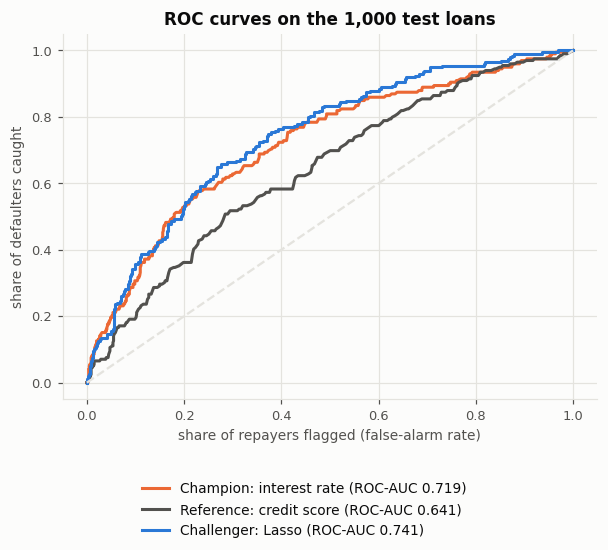

,Corporate,Retail,Whole book
Loans,"1,306.000","3,694.000","5,000.000"
₹ lent (crore),173.224,466.429,639.653
Default rate,0.200,0.199,0.199
Default rate (money),0.256,0.241,0.245
Average loan (₹ lakh),13.264,12.627,12.793
Interest rate (₹-weighted),0.104,0.103,0.103
Average credit score,687.743,688.926,688.617
Average debt-to-income,0.383,0.387,0.386
Past default share,0.112,0.111,0.111
Interest − actual loss at 40% (crore),0.247,2.828,3.075


Retail vs Corporate default rate: chi-square p = 0.995


,All loans,Corporate,Retail
Sector_Risk,,,
Lowest,18.2%,19.2%,17.8%
Low,19.5%,16.5%,20.6%
Middle,20.0%,19.6%,20.1%
High,21.3%,22.8%,20.8%
Highest,20.7%,21.9%,20.3%


Sector risk: fifths differ? chi-square p = 0.47;  steady trend? correlation +0.029, p = 0.042


One model serves both segments (no segment-specific approach improves Brier): True


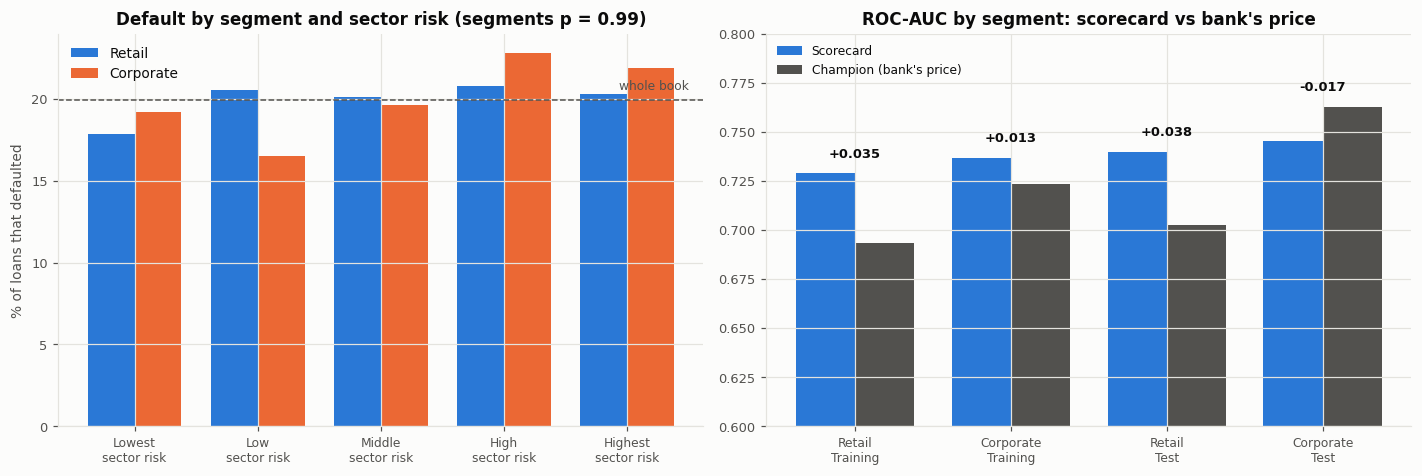

{'default_rate': {'Retail': 0.1992, 'Corporate': 0.1998}, 'segment_p': 0.995, 'sector_p': 0.472, 'sector_trend_p': 0.042, 'earn_crore': {'Retail': 2.83, 'Corporate': 0.25}, 'auc_gain_oof': {'Retail': 0.035, 'Corporate': 0.013}, 'brier_vs_one': {'One model for both (chosen)': 0.0, 'Separate model per segment': 0.0005, 'One model with segment interactions': 0.0001}, 'one_model_ok': True}


,Input,Weight b (per 1 std),Odds ratio e^b,Effect on default odds
0,Credit_Score,-0.451,0.64,lowers odds by 36%
1,Debt_to_Income,+0.423,1.53,raises odds by 53%
2,Past_Default,+0.338,1.40,raises odds by 40%
3,Loan_Amount,+0.159,1.17,raises odds by 17%
4,Loan_to_Income,+0.121,1.13,raises odds by 13%
5,Total_Debt_to_Income,+0.111,1.12,raises odds by 12%
6,Collateral_Value,+0.037,1.04,raises odds by 4%
7,Loan_Term_Months,+0.000,1.00,switched off (weight 0)
8,Existing_Loan,+0.000,1.00,switched off (weight 0)
9,Annual_Income,+0.000,1.00,switched off (weight 0)


Lasso penalty chosen by inner CV on the 4,000 loans: C = 0.0464 (λ = 1 ÷ C = 21.54); inputs kept: 7 of 15


,Input,Mean |SHAP|
0,Credit_Score,0.367
1,Debt_to_Income,0.348
2,Past_Default,0.213
3,Loan_Amount,0.112
4,Loan_to_Income,0.105
5,Total_Debt_to_Income,0.094
6,Collateral_Value,0.024
7,Loan_Term_Months,0.000
8,Existing_Loan,0.000
9,Annual_Income,0.000


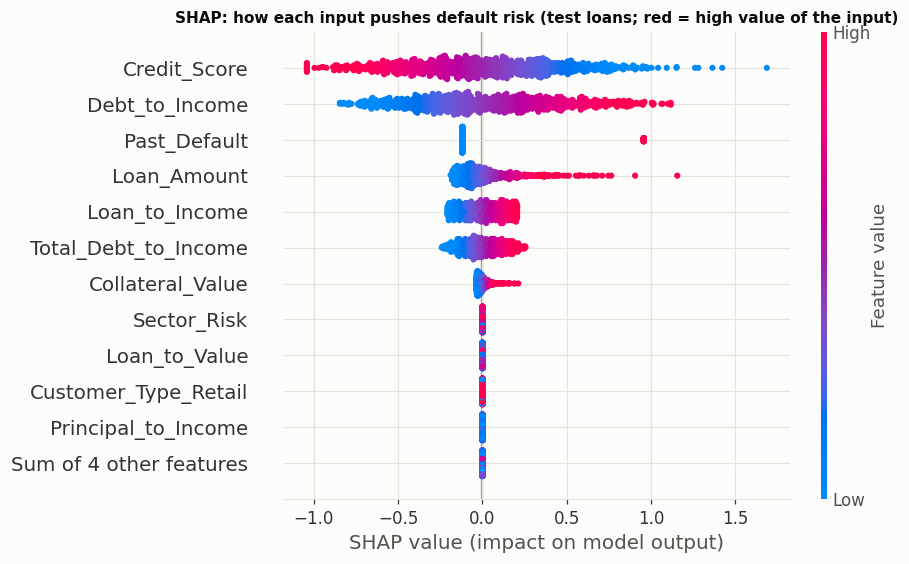

,Example,Loan_ID,Customer_Type,Loan (₹ lakh),Credit_Score,Debt_to_Income,Past_Default,Rate charged (%),Champion PD,Challenger PD,Expected loss (₹ lakh),Actually defaulted?,Top 3 drivers (SHAP push)
0,Low risk,200656,Retail,2.0,820,0.33,0,7.56,10.1%,4.9%,0.04,No,Credit_Score -0.85; Loan_Amount -0.16; Loan_to_Income -0.13
1,Middle,201102,Corporate,1.1,755,0.42,1,9.89,19.8%,17.9%,0.08,No,Past_Default +0.96; Credit_Score -0.43; Total_Debt_to_Income -0.22
2,High risk,201025,Retail,22.8,540,0.09,1,15.38,61.0%,56.7%,5.18,Yes,Credit_Score +0.96; Past_Default +0.96; Debt_to_Income -0.70


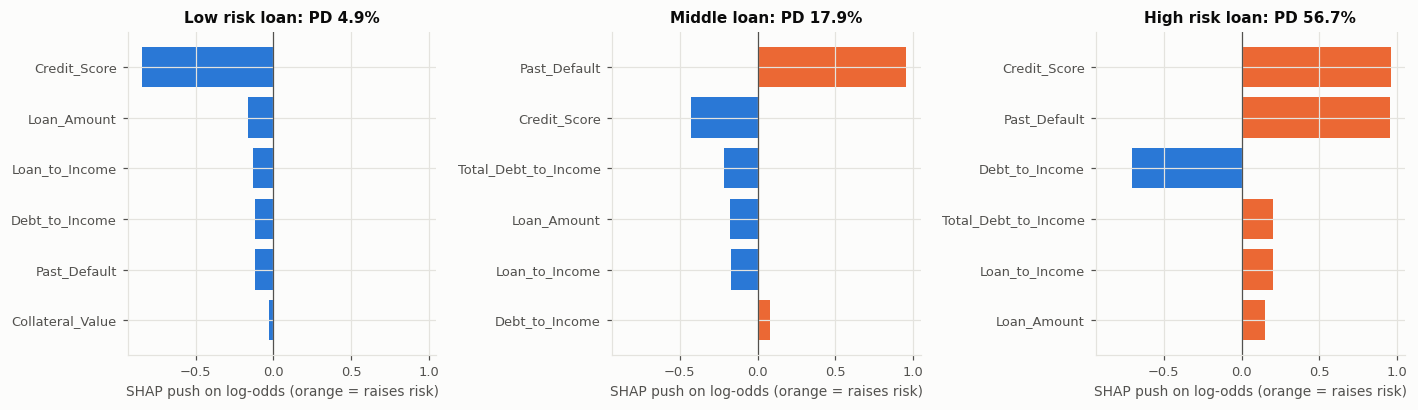

{
 "chosen": "Lasso",
 "rupee_turning_point": 0.73,
 "delong_p": 0.0647
}
Saved to module_02_credit_risk/outputs/task1
['01_default_rate_by_input.png', '02_loan_book_board_view.png', '03_collateral_and_term.png', '04_cv_comparison.png', '05_overfitting_check.png', '06_rupee_losses_by_approval.png', '07_test_roc_curves.png', '08_shap_summary.png', '09_example_loans_shap.png', '10_segments.png', 'FINAL_M2_T1_default_predictions.csv', 'all_models_vs_chosen.csv', 'chosen_model.joblib', 'chosen_model.json', 'collateral_cover.csv', 'cv_rounds.csv', 'cv_summary.csv', 'default_by_term.csv', 'default_rate_by_input.csv', 'example_loans.csv', 'key_numbers.json', 'loan_book_board_view.csv', 'mispriced_loans.csv', 'model_inputs.csv', 'model_weights_odds_ratios.csv', 'overfitting_check.csv', 'paired_vs_best.csv', 'paired_vs_champion.csv', 'rebalancing_evidence.csv', 'rupee_same_approval.csv', 'rupee_same_default_rate.csv', 'rupee_sweep.csv', 'sector_risk_default.csv', 'segment_model_performance.csv'

In [3]:
%run notebooks/m02_task1_pd_model.ipynb

## 2. Task 2 — PD per loan and risk bands
Runs `notebooks/m02_task2_pd_bands.ipynb` (under a minute). Reads `outputs/task1/FINAL_M2_T1_default_predictions.csv`, so Task 1 must have run first.
- calibration: can each PD be trusted as a probability (four checks, Platt scaling only if needed);
- the brief's four risk bands tested (inside range, rising clearly, enough loans, economics);
- the bands in ₹, and where the scorecard disagrees with the bank's pricing;
- saves `outputs/task2/loan_pd.csv` (Loan_ID, Predicted_PD, Risk_Category) and the hand-off for Task 3.

Project folder found
Reads from:     module_02_credit_risk/outputs/task1
Outputs go to:  module_02_credit_risk/outputs/task2


,Loans,Defaults,Default_rate,Average_PD
Set,,,,
test,1000,199,19.90%,21.16%
train (out-of-fold),4000,798,19.95%,20.22%


All 5,000 loans have an honest PD (challenger) and the champion's PD.


,"All 5,000 loans","1,000 test loans"
Loans,5000,1000
Average PD,0.204105,0.211567
Actual default rate,0.1994,0.199
1. Intercept a,-0.032861,-0.085895
a 95% low,-0.106414,-0.249677
a 95% high,0.040691,0.077886
1. Pass,True,True
2. Slope b,1.044404,1.126674
b 95% low,0.95049,0.904481
b 95% high,1.138319,1.348867


All four checks pass on both sets.


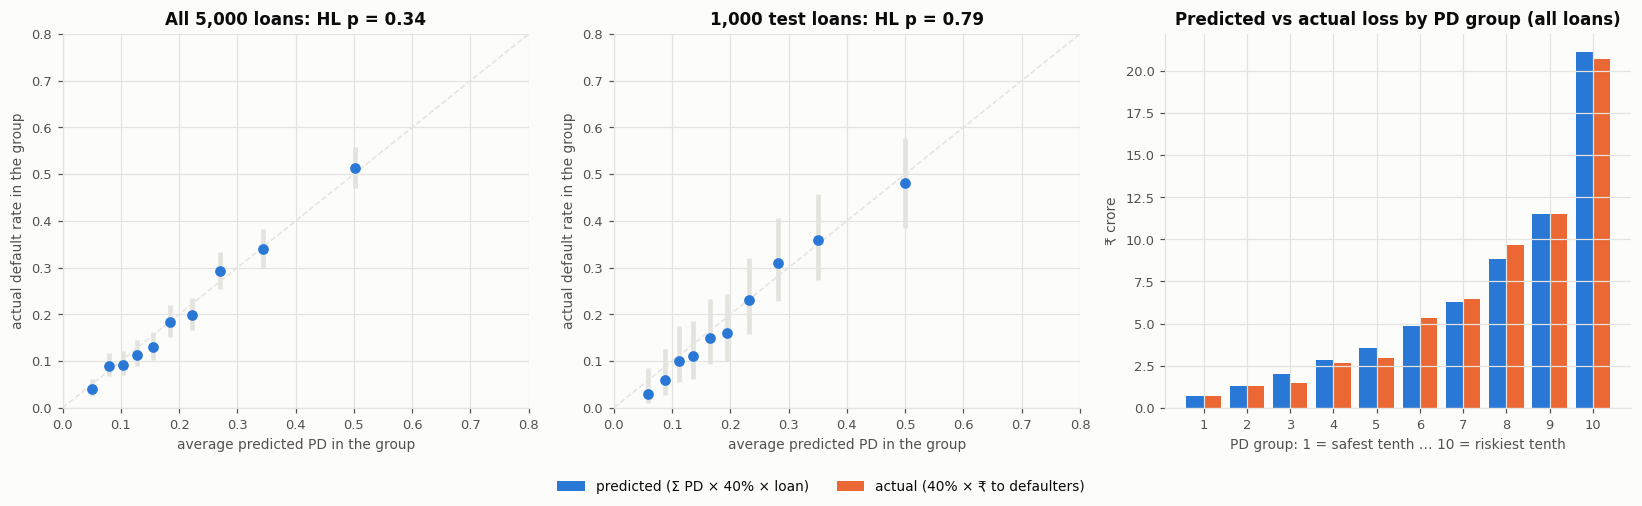

Platt scaling NOT applied: all four calibration checks pass on all 5,000 and on the 1,000 test loans.
Predicted_PD = the lasso PD from Task 1, unchanged.


,Loans,Share
Risk_Category,,
Low,220,4.4%
Medium,1935,38.7%
High,1824,36.5%
Very High,1021,20.4%


Merges needed: none: the brief's four bands are kept
ALL 5,000 LOANS (deciding)


,Range,Loans,Defaults,Actual default rate,95% low,95% high,Average PD,① Inside range,Range width,Band width,③ Enough loans,Average interest (%),Expected loss a year (%),Margin (%)
Risk_Category,,,,,,,,,,,,,,
Low,0% to under 5%,220,7,3.2%,1.5%,6.4%,4.0%,True,4.9%,5%,True,7.54,1.59,+5.95
Medium,5% to under 15%,1935,180,9.3%,8.1%,10.7%,10.1%,True,2.6%,10%,True,8.11,4.04,+4.07
High,15% to under 30%,1824,374,20.5%,18.7%,22.4%,21.2%,True,3.7%,15%,True,9.59,8.49,+1.10
Very High,30% and above,1021,436,42.7%,39.7%,45.8%,42.1%,True,6.1%,15%,True,12.51,16.82,-4.31


,Step,Lower band rate,Upper band rate,z,p-value,Pass
0,Low → Medium,3.2%,9.3%,3.06,0.0011,True
1,Medium → High,9.3%,20.5%,9.68,1.8e-22,True
2,High → Very High,20.5%,42.7%,12.59,1.3e-36,True


② Chi-square across bands = 507.6 (3 degrees of freedom), p = 1.1e-109  →  rising clearly: True
④ Economics (margin falls band to band and is negative for the riskiest band): True
1,000 TEST LOANS (consistency check)


,Range,Loans,Defaults,Actual default rate,95% low,95% high,Average PD,① Inside range,Range width,Band width,③ Enough loans,Average interest (%),Expected loss a year (%),Margin (%)
Risk_Category,,,,,,,,,,,,,,
Low,0% to under 5%,24,0,0.0%,0.0%,13.8%,4.2%,True,13.8%,5%,False,7.61,1.70,+5.91
Medium,5% to under 15%,376,30,8.0%,5.6%,11.2%,10.2%,True,5.5%,10%,True,8.10,4.09,+4.01
High,15% to under 30%,383,82,21.4%,17.6%,25.8%,21.4%,True,8.2%,15%,True,9.48,8.56,+0.92
Very High,30% and above,217,87,40.1%,33.8%,46.7%,41.5%,True,12.9%,15%,True,12.54,16.61,-4.07


,Step,Lower band rate,Upper band rate,z,p-value,Pass
0,Low → Medium,0.0%,8.0%,1.44,0.075,False
1,Medium → High,8.0%,21.4%,5.22,9.1e-08,True
2,High → Very High,21.4%,40.1%,4.89,5.1e-07,True


① Every band's actual rate inside its range: True
Rates rise band to band: True
② and ③ (reported only): chi-square p = 1.4e-20; step tests passing: 2 of 3; bands with enough test loans: 3 of 4


,Test,"All 5,000 loans (deciding)","1,000 test loans"
0,① Inside its range,True,True
1,② Rising clearly,True,order rises; significance reported only
2,③ Enough loans,True,reported only
3,④ Economics,True,True


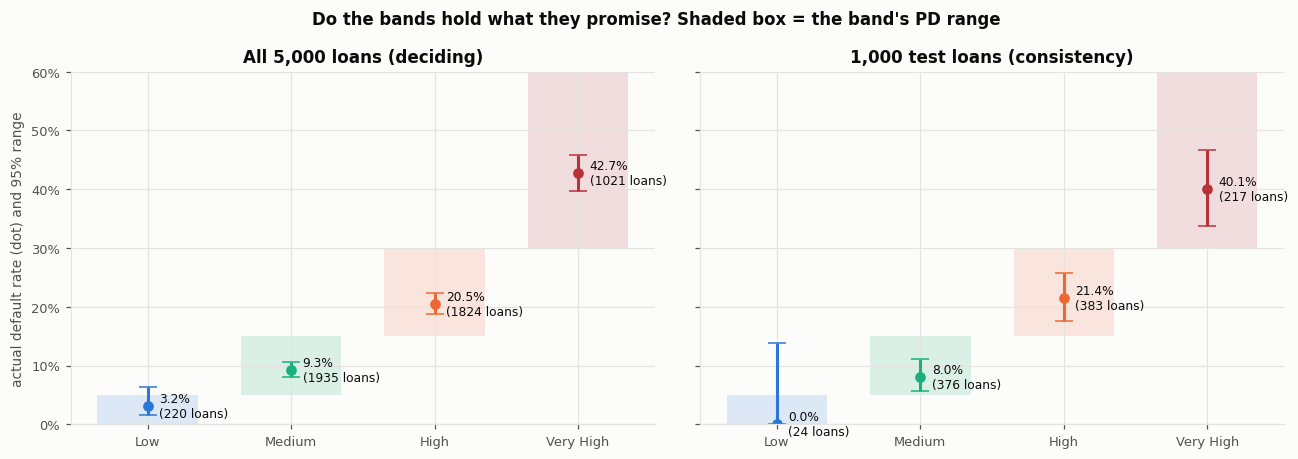

,Loans,₹ lent (crore),Interest a year (crore),Expected loss a year (crore),Actual loss at 40% (crore),Share of loans,Share of ₹ lent,Share of expected loss,Interest minus expected loss (crore)
Risk_Category,,,,,,,,,
Low,220,13.3,1.0,0.2,0.1,4.4%,2.1%,0.3%,0.8
Medium,"1,935",180.5,14.8,7.6,6.8,38.7%,28.2%,12.0%,7.3
High,"1,824",256.1,25.2,22.2,23.0,36.5%,40.0%,35.3%,3.0
Very High,"1,021",189.8,24.8,33.0,32.7,20.4%,29.7%,52.4%,-8.3
Whole book,"5,000",639.7,65.8,63.0,62.7,100.0%,100.0%,100.0%,2.8


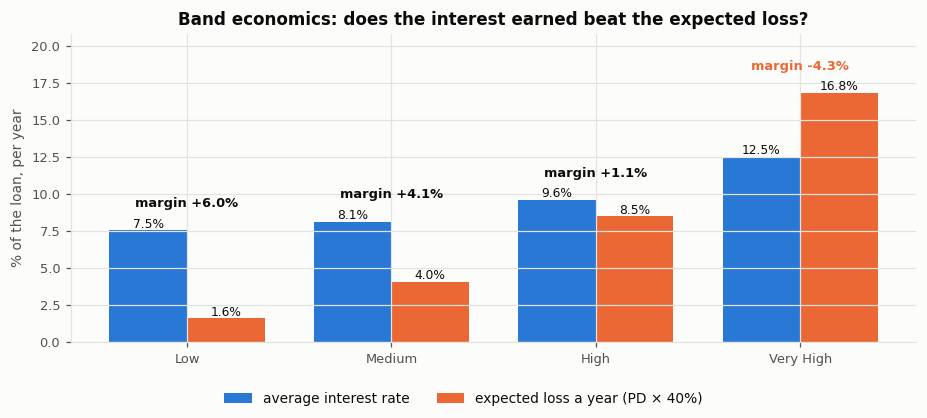

Same band under both views: 66.4% of loans
The bank's price never signals Low risk: its lowest PD is 6.1% (at the 6.0% floor rate), so no loan falls below 5%. The scorecard places 220 loans there.
Loans (rows = bank's view from its price, columns = scorecard):


Risk_Category,Low,Medium,High,Very High
Champion_Category,,,,
Low,0,0,0,0
Medium,198,1505,554,11
High,22,428,1128,322
Very High,0,2,142,688


Actual default rate in each cell:


Risk_Category,Low,Medium,High,Very High
Champion_Category,,,,
Low,—,—,—,—
Medium,3.0%,9.5%,15.5%,45.5%
High,4.5%,8.6%,21.5%,34.5%
Very High,—,0.0%,32.4%,46.5%


₹ lent in each cell (crore):


Risk_Category,Low,Medium,High,Very High
Champion_Category,,,,
Low,0.0,0.0,0.0,0.0
Medium,11.5,136.0,64.6,1.4
High,1.7,44.1,159.3,45.7
Very High,0.0,0.3,32.2,142.6


,Group,Loans,₹ lent (crore),Actual default rate,Average rate charged (%)
0,Scorecard puts in a SAFER band than the bank's price,792,89.9,11.4%,9.45
1,Same band,3321,438.0,21.2%,9.67
2,Scorecard puts in a RISKIER band than the bank's price,887,111.8,22.8%,9.05


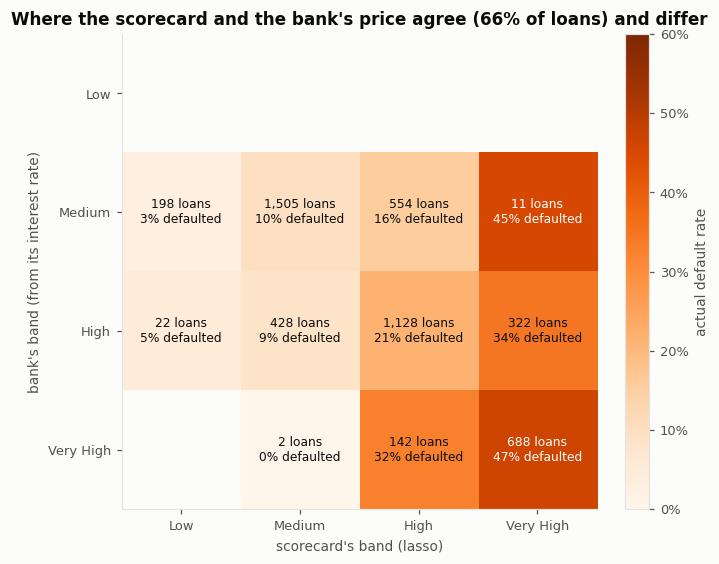

   Loan_ID  Predicted_PD Risk_Category
0   200001      0.188580          High
1   200002      0.076655        Medium
2   200003      0.085960        Medium
3   200004      0.476837     Very High
4   200005      0.187931          High
Saved to module_02_credit_risk/outputs/task2
['01_calibration.png', '02_band_tests.png', '03_band_economics.png', '04_scorecard_vs_bank_bands.png', 'FINAL_M2_T2_risk_categories.csv', 'band_by_customer_type.csv', 'band_rupee_profile.csv', 'band_step_tests.csv', 'band_tests_all_loans.csv', 'band_tests_test_loans.csv', 'band_tests_verdict.csv', 'calibration_checks.csv', 'calibration_rupees_by_group.csv', 'cross_bands_default_rate.csv', 'cross_bands_disagreement.csv', 'cross_bands_loans.csv', 'cross_bands_rupees.csv', 'key_numbers.json', 'loan_pd.csv']


In [4]:
%run notebooks/m02_task2_pd_bands.ipynb

## 3. Task 3 — Expected Credit Loss and the Approve / Review / Reject decision
Runs `notebooks/m02_task3_ecl_decision.ipynb` (under a minute). Reads `outputs/task2/FINAL_M2_T2_risk_categories.csv`, so Tasks 1 and 2 must have run first.
- ECL = PD × 40% × loan amount for every loan, and in ₹ by band;
- the agreed rule (PD, ECL, loan size, collateral, risk appetite), with a reason and a required rate for every loan;
- the result in ₹ against today's book, checked on the 1,000 test loans;
- risk-appetite trade-off, cost-of-lending and LGD sensitivities, scorecard vs the bank's own view;
- saves `outputs/task3/FINAL_M2_T3_loan_decisions.csv`.

Project folder found
Reads from:     module_02_credit_risk/outputs/task2
Outputs go to:  module_02_credit_risk/outputs/task3
Loans: 5,000  (training 4,000, test 1,000)
Loan book: ₹639.7 crore;  actual default rate 19.9%
Task 1's ₹ turning point: 73% approval


Total ECL: ₹63.04 crore a year on ₹639.7 crore (actual loss at 40%: ₹62.72 crore)
Largest single ECL: ₹37.6 lakh;  median: ₹0.67 lakh


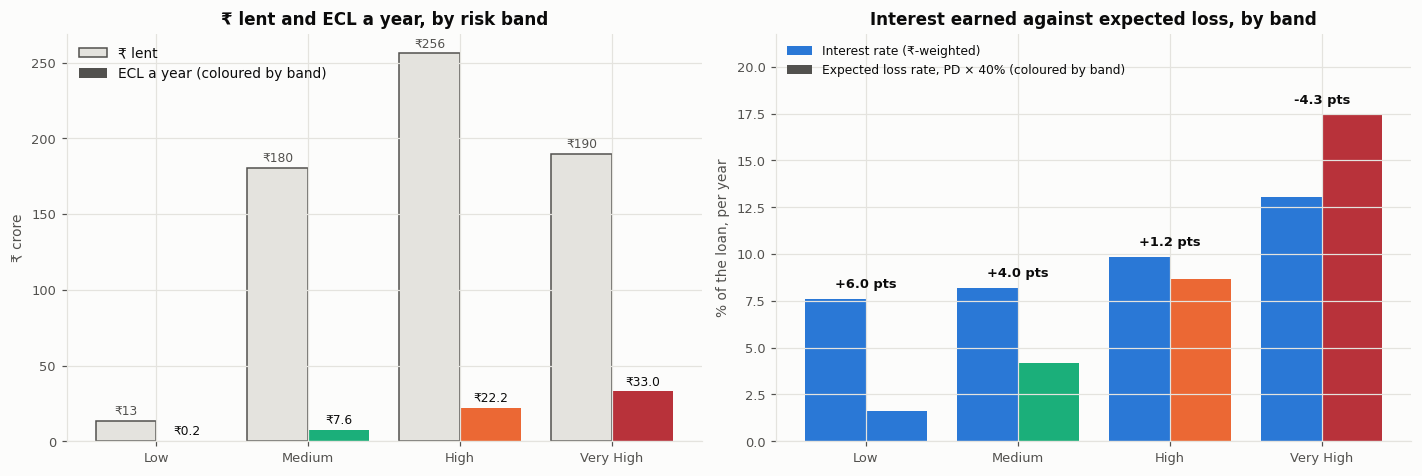

Size cut-off (largest 5%): ₹33.3 lakh
Decision
Approve    2934
Review     1045
Reject     1021
Loans passing steps 1 and 2: 3,542
Groups where the gap is bigger than chance (p < 0.05): 0 of 24
1) Does collateral predict default?  p = 0.77 (two-sided test of the two default rates)
                        Loans  Actual_default  Average_PD
Covered                                                  
Loan above collateral    1210           0.126       0.131
Loan within collateral   2332           0.130       0.138

2) Average collateral-aware LGD at 50% recovery: 37.4% by loan count, 37.5% weighted by ₹ (brief: 40%)


Approve default rate 11.3% vs today's 19.9%: z = -9.9, p = 2.3e-23
Approve earns ₹10.45 crore a year above actual loss (95% range ₹8.62 to ₹12.11 crore); today's whole book ₹3.07 crore
Consistent on the test loans (rising default, Approve below today's): True


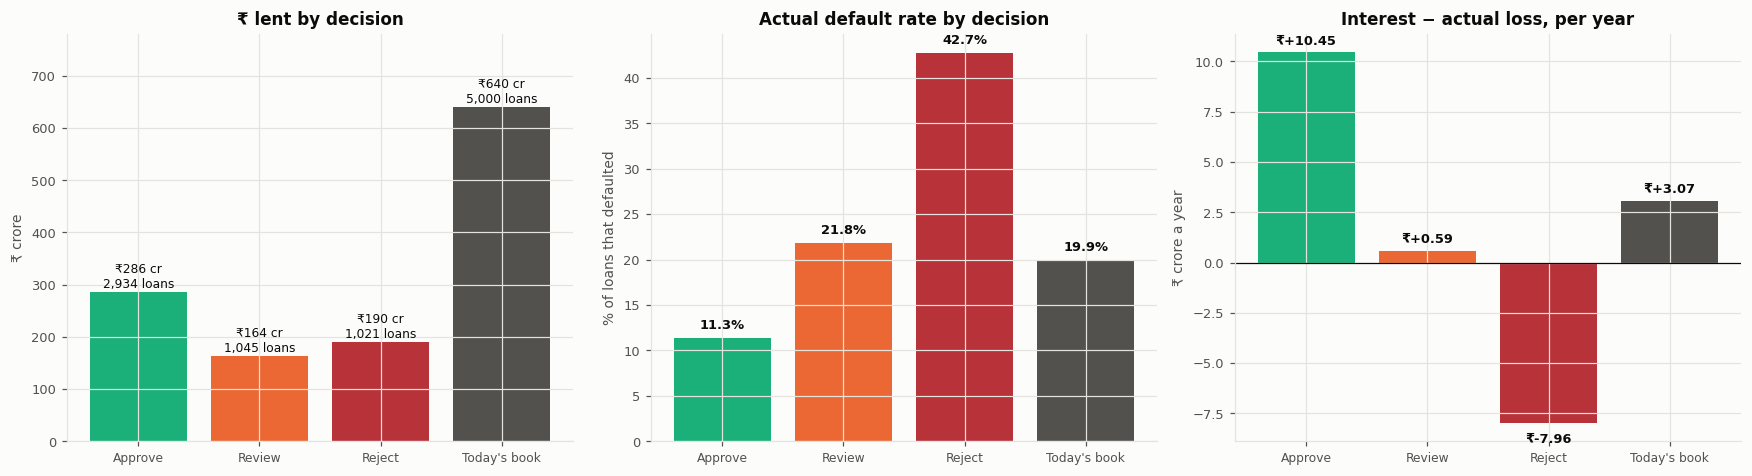

Does the agreed 6% cap move any loan? False


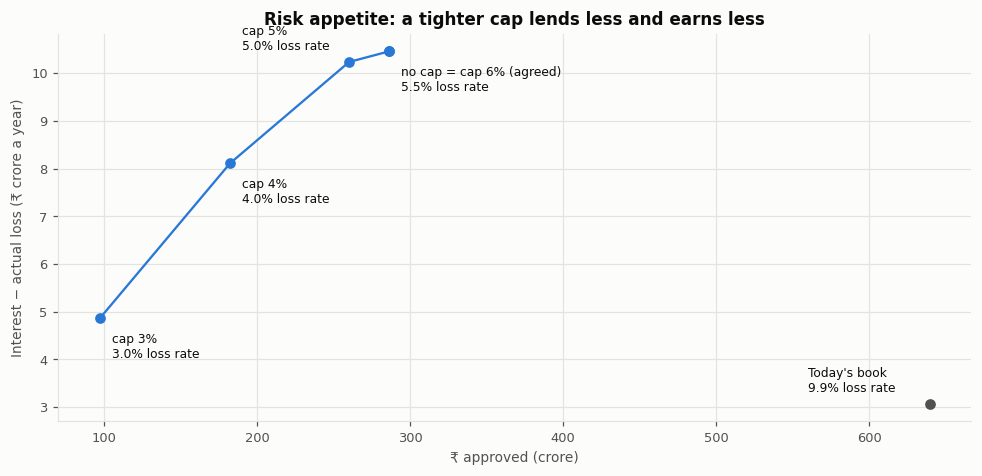

Today's book breaks even at a cost of 0.48% a year; above that it loses money.


Loans bigger than their collateral: 1,665 (₹212.7 crore)


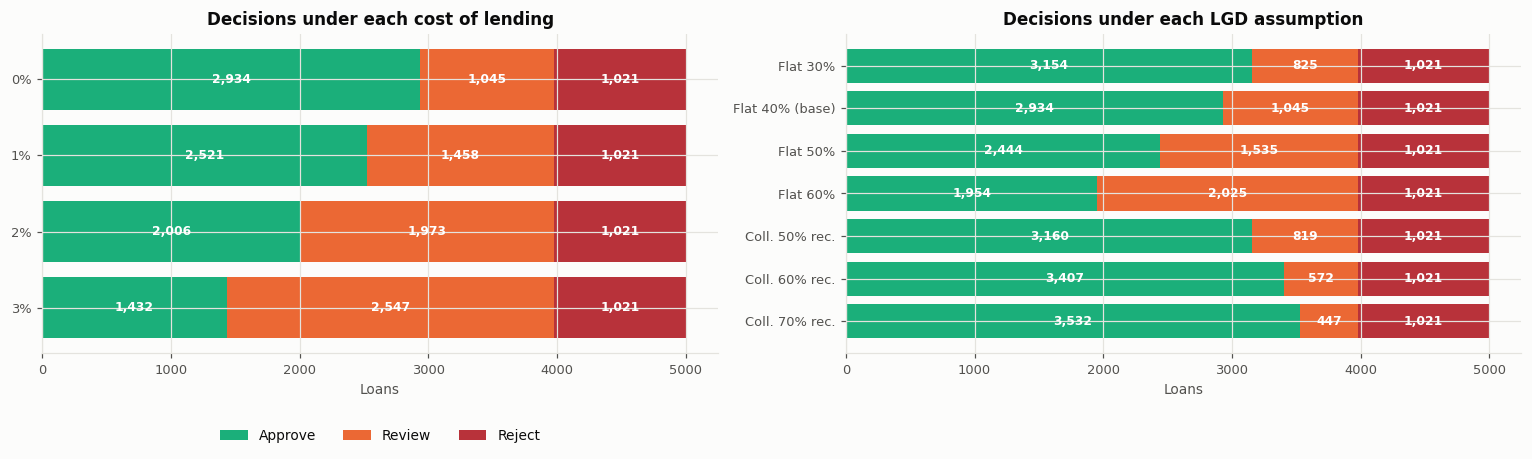

The rule approves 58.7% of loans (steps 1–2 alone: 70.8%); Task 1 turning point: 73%


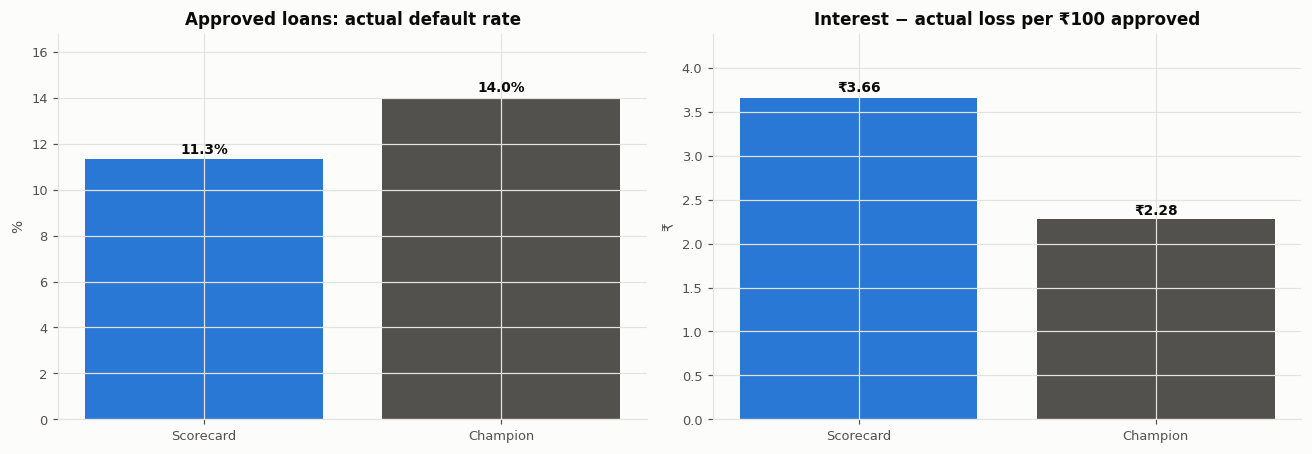

Approved loans, Retail vs Corporate default rate: p = 0.98


Today, ₹ earned per ₹100 lent, 95% range — Retail: ₹-0.09 to ₹+1.33
Today, ₹ earned per ₹100 lent, 95% range — Corporate: ₹-1.02 to ₹+1.40
Today, ₹ earned per ₹100 lent, 95% range — Retail − Corporate: ₹-0.90 to ₹+1.91
Is Corporate's lower earning today bigger than chance? False


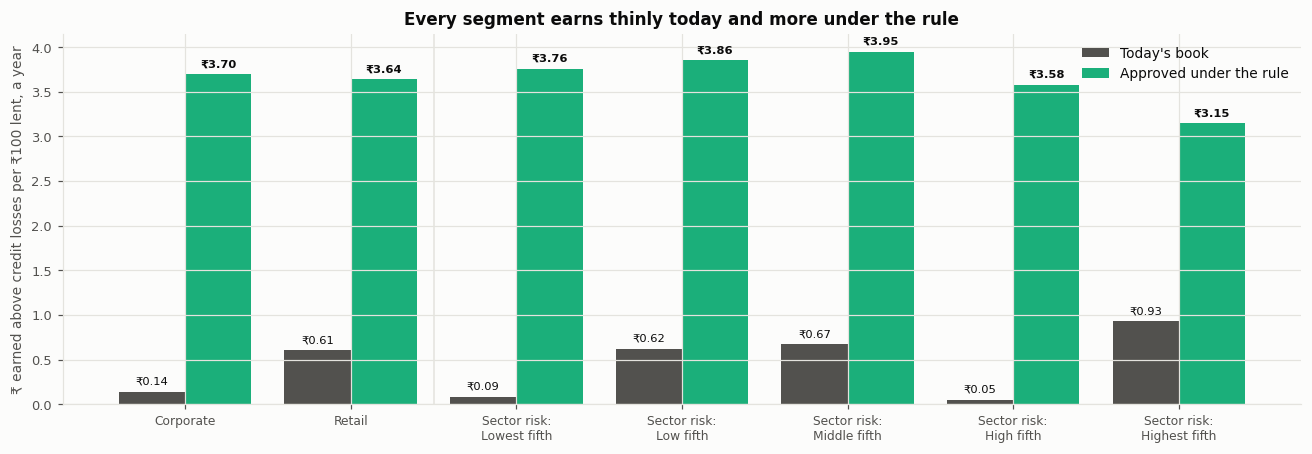

,Group,Loan type,Loans,₹ lent (crore),Interest rate (%),Expected loss (%),Return per ₹ lent (% a year),What it really earned (% a year),Bad year: PD × 2 (% a year),"Severe year: PD × 2, LGD 60% (% a year)","1-in-100 year, luck alone (% a year)"
0,Approve,Retail,2169,210.52,8.73,5.44,3.30,3.64,-2.14,-7.58,2.45
1,Approve,Corporate,765,75.42,8.81,5.50,3.31,3.70,-2.19,-7.68,1.80
2,Approve,All,2934,285.94,8.75,5.45,3.30,3.66,-2.15,-7.61,2.60
3,Review,Retail,773,120.32,9.80,8.84,0.96,0.08,-7.88,-16.73,-0.81
4,Review,Corporate,272,43.61,9.63,8.66,0.97,1.12,-7.68,-16.34,-2.05
5,Review,All,1045,163.93,9.76,8.79,0.96,0.36,-7.83,-16.62,-0.51


Approved loans earn 3.3% a year above expected losses, but a recession year (PD × 2) turns that into -2.2% (-7.6% if collateral fetches less). The Review queue earns about 1% even in a normal year. All figures are before the cost of funds (not in the data).


,Category,Return per ₹ deployed (% a year),Bad-year result per ₹ (% a year),Capacity (₹ crore)
0,Retail lending,3.30,-2.14,210.52
1,Corporate lending,3.31,-2.19,75.42


,0,3,7
Loan_ID,200001,200004,200008
Customer_Type,Corporate,Corporate,Corporate
Loan_Amount (₹),1968503.82,3855380.75,2015226.77
Collateral_Value (₹),2690085.58,5571538.48,2343021.65
Predicted_PD,0.18858,0.476837,0.281094
Risk_Category,High,Very High,High
ECL a year (₹),148488.18,735355.28,226587.26
Interest a year (₹),176377.94,500042.88,176332.34
Rate charged (%),8.96,12.97,8.75
Expected loss rate (%),7.543,19.073,11.244


                     crore    rate  ecl_rate  expected_return
Retail_book         466.43  0.1025    0.0975           0.0050
Retail_approved     210.52  0.0873    0.0544           0.0330
Corporate_book      173.22  0.1037    0.1013           0.0024
Corporate_approved   75.42  0.0881    0.0550           0.0331
All_book            639.65  0.1029    0.0986           0.0043
All_approved        285.94  0.0875    0.0545           0.0330
   Loan_ID Customer_Type  Loan_Amount (₹)  Collateral_Value (₹)  Predicted_PD Risk_Category  ECL a year (₹)  Interest a year (₹)  Rate charged (%)  Expected loss rate (%)  Expected return (%)  Required rate (%)  \
0   200001     Corporate       1968503.82            2690085.58      0.188580          High       148488.18            176377.94              8.96                   7.543                1.417              7.543   
1   200002        Retail       1932554.81            2542892.81      0.076655        Medium        59256.00            151125.79          

In [5]:
%run notebooks/m02_task3_ecl_decision.ipynb

## Final output workbook
Builds **`outputs/FINAL_M2_module_output.xlsx`**: the one file to open for this module's results (project decision P-21).
- Tabs: Read me · Key numbers · Board actions · each task's final file · Hand-off to Module 9 · Decisions · Evidence index.
- Every hand-off figure is computed from the task tabs' rows, and each row says which tab, column(s) and rows it comes from.
- Run after all the tasks above.

In [6]:
%run helpers/m02_final_output.py

Saved: FINAL_M2_module_output.xlsx
                                             Figure                                                                                                                                        Value                                                 Unit
                   Retail lending, approved: ₹ lent                                                                                                                                       210.52                                              ₹ crore
   Retail lending, approved: expected return a year                                                                                                                                          3.3 % of ₹ lent (before cost of funds and running costs)
                Corporate lending, approved: ₹ lent                                                                                                                                        75.42                                   